In [3]:
import pandas as pd
df = pd.read_csv(r"C:\Users\Aarya\OneDrive\Desktop\Superstore Sales & Profit Analysis\Dataset\Sample_Superstore.csv", encoding="cp1252")
# Fixing date formats
df['Order Date'] = pd.to_datetime(df['Order Date'], format='mixed')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='mixed')
print("Duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())

Duplicate rows: 0
Missing values: 0


In [17]:
print("--- OVERALL NUMBERS ---")
print("Total Sales: $", round(df['Sales'].sum(), 2))
print("Total Profit: $", round(df['Profit'].sum(), 2))

print("\n--- PROFIT BY CATEGORY ---")
print(df.groupby('Category')['Profit'].sum())

print("\n--- SALES BY REGION ---")
print(df.groupby('Region')['Sales'].sum())

print("\n--- MOST POPULAR SHIPPING MODE ---")
print(df['Ship Mode'].value_counts())

# Task 8:  Top earners & Loss makers
print("--- SUB-CATEGORY PERFORMANCE ---")
subcat = df.groupby('Sub-Category')[['Sales', 'Profit']].sum().sort_values(by='Profit', ascending=False)
print("Top 3 Profitable:\n", subcat.head(3))
print("\nBottom 3 (Loss-Makers):\n", subcat.tail(3))

# Task 9: Customer Segment Analysis
print("\n--- CUSTOMER SEGMENT ANALYSIS ---")
print(df.groupby('Segment')[['Sales', 'Profit']].sum())

--- OVERALL NUMBERS ---
Total Sales: $ 2297200.86
Total Profit: $ 286397.02

--- PROFIT BY CATEGORY ---
Category
Furniture           18451.2728
Office Supplies    122490.8008
Technology         145454.9481
Name: Profit, dtype: float64

--- SALES BY REGION ---
Region
Central    501239.8908
East       678781.2400
South      391721.9050
West       725457.8245
Name: Sales, dtype: float64

--- MOST POPULAR SHIPPING MODE ---
Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64
--- SUB-CATEGORY PERFORMANCE ---
Top 3 Profitable:
                    Sales      Profit
Sub-Category                        
Copiers       149528.030  55617.8249
Phones        330007.054  44515.7306
Accessories   167380.318  41936.6357

Bottom 3 (Loss-Makers):
                     Sales      Profit
Sub-Category                         
Supplies       46673.5380  -1189.0995
Bookcases     114879.9963  -3472.5560
Tables        206965.5320 -17725.4

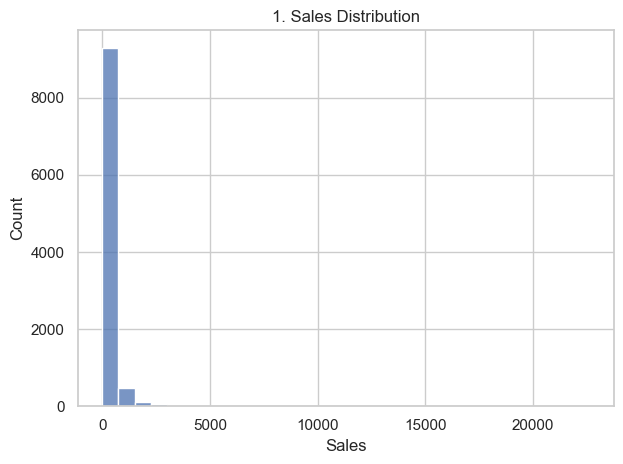

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Sales histogram
plt.figure()
sns.histplot(df['Sales'], bins=30)
plt.title("1. Sales Distribution")
plt.show()



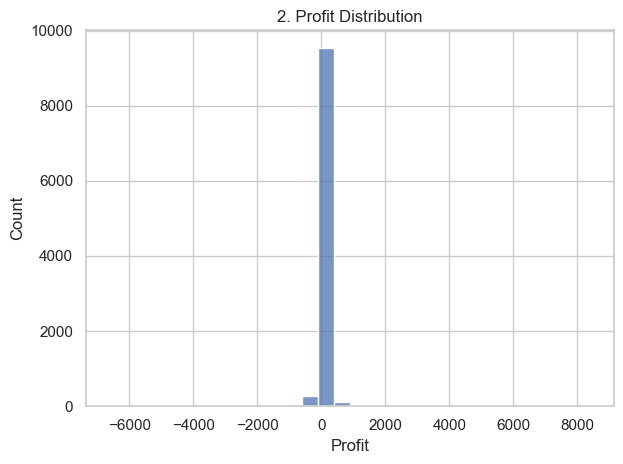

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
# 2. Profit histogram
plt.figure()
sns.histplot(df['Profit'], bins=30)
plt.title("2. Profit Distribution")
plt.show()


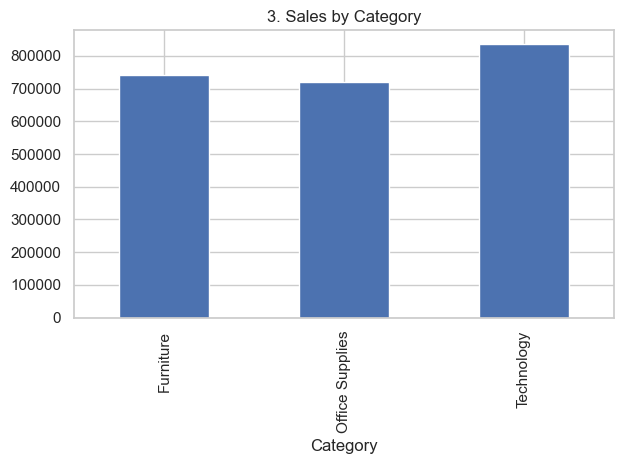

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
# 3. Category Sales
plt.figure()
df.groupby('Category')['Sales'].sum().plot(kind='bar')
plt.title("3. Sales by Category")
plt.show()


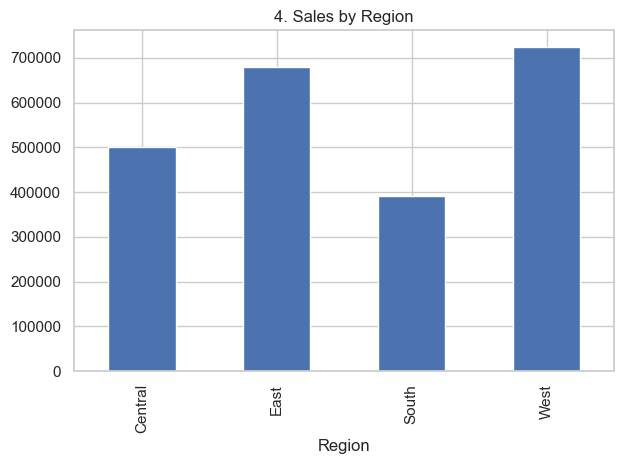

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
# 4. Region Sales
plt.figure()
df.groupby('Region')['Sales'].sum().plot(kind='bar')
plt.title("4. Sales by Region")
plt.show()


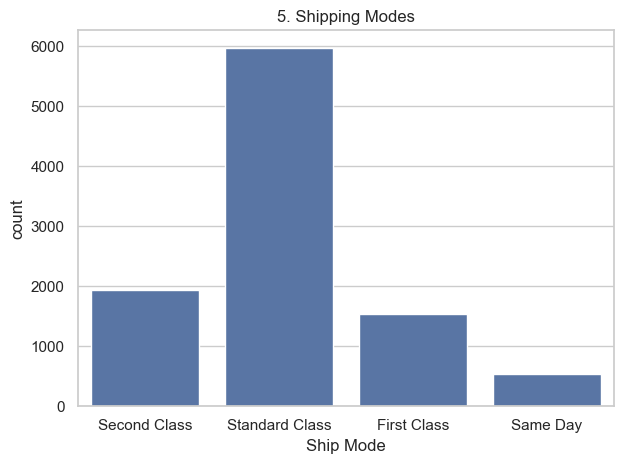

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
# 5. Shipping Mode Count
plt.figure()
sns.countplot(data=df, x='Ship Mode')
plt.title("5. Shipping Modes")
plt.show()


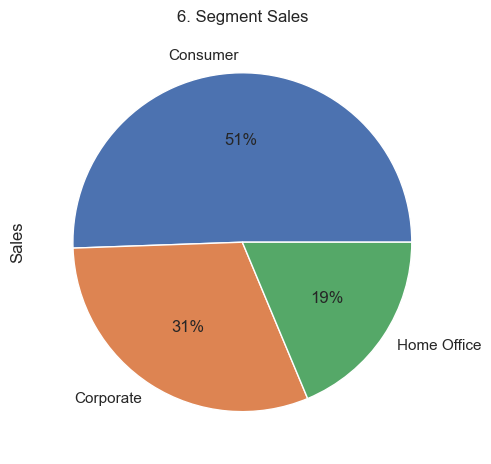

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
# 6. Customer Segment Pie Chart
plt.figure()
df.groupby('Segment')['Sales'].sum().plot(kind='pie', autopct='%1.0f%%')
plt.title("6. Segment Sales")
plt.show()


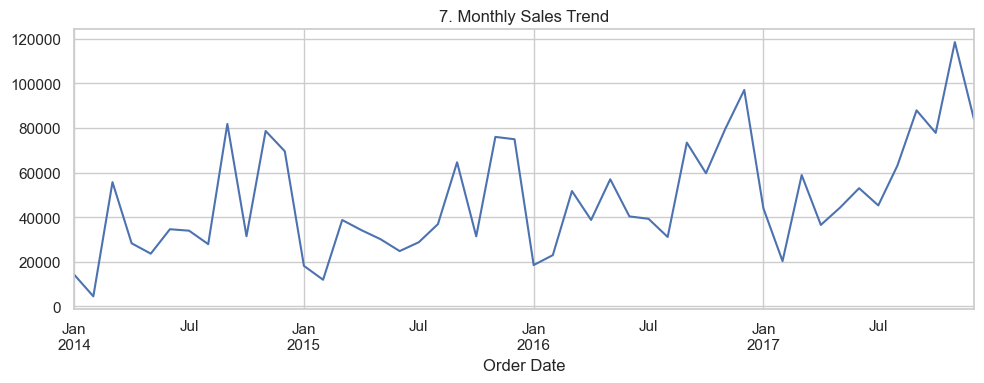

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
# 7. Monthly Sales Trend
plt.figure(figsize=(10, 4))
df.set_index('Order Date').resample('ME')['Sales'].sum().plot()
plt.title("7. Monthly Sales Trend")
plt.show()


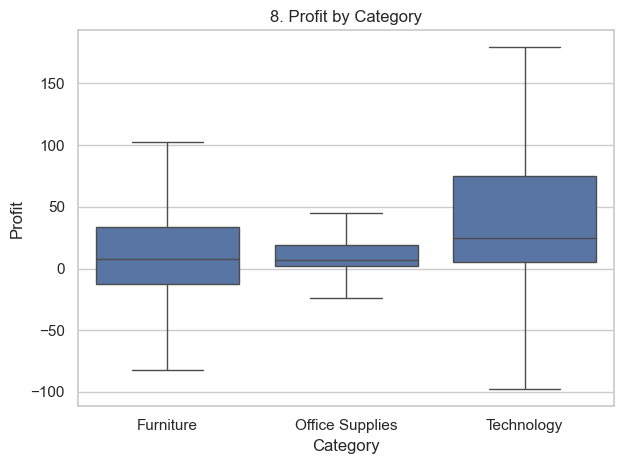

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
# 8. Profit Box Plot
plt.figure()
sns.boxplot(data=df, x='Category', y='Profit', showfliers=False)
plt.title("8. Profit by Category")
plt.show()


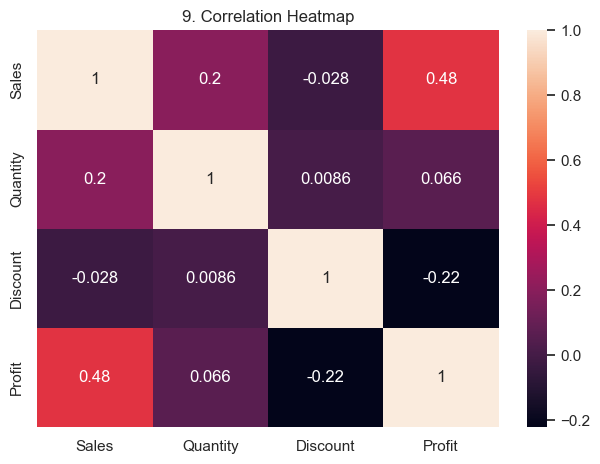

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
# 9. Correlation Heatmap
plt.figure()
sns.heatmap(df[['Sales', 'Quantity', 'Discount', 'Profit']].corr(), annot=True)
plt.title("9. Correlation Heatmap")
plt.show()


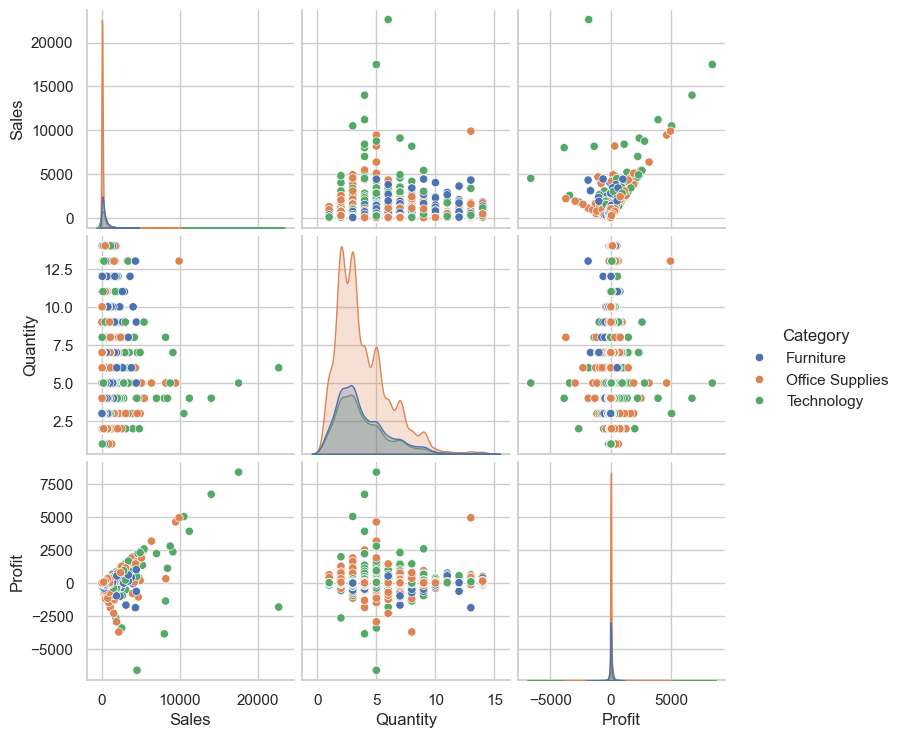

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
# 10. Pair Plot
sns.pairplot(df[['Sales', 'Quantity', 'Profit', 'Category']], hue='Category')
plt.show()

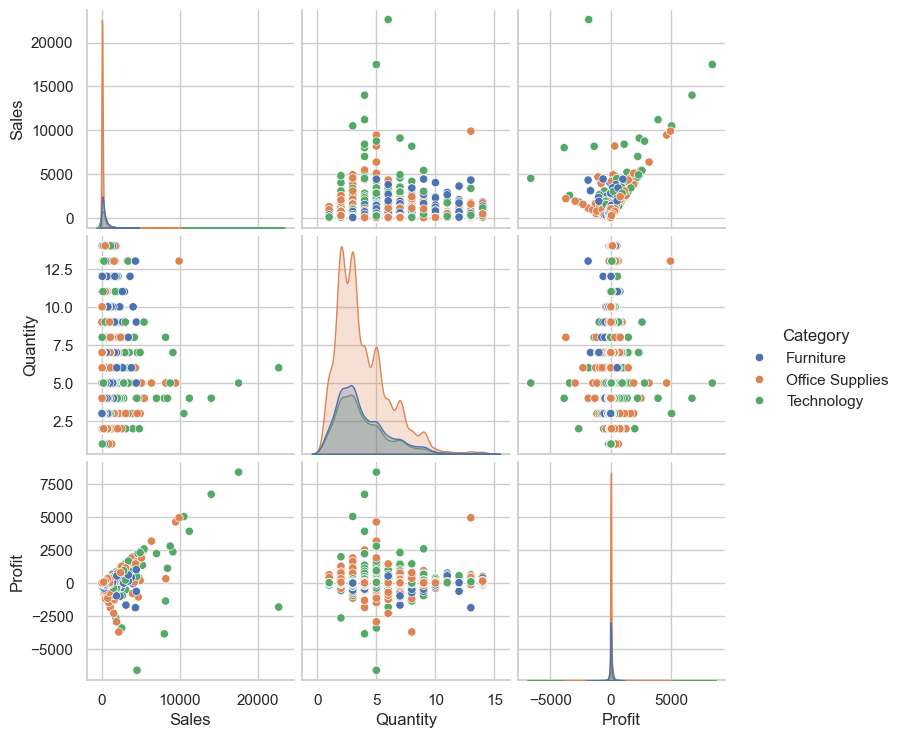

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
# 10. Pair Plot
sns.pairplot(df[['Sales', 'Quantity', 'Profit', 'Category']], hue='Category')
plt.show()

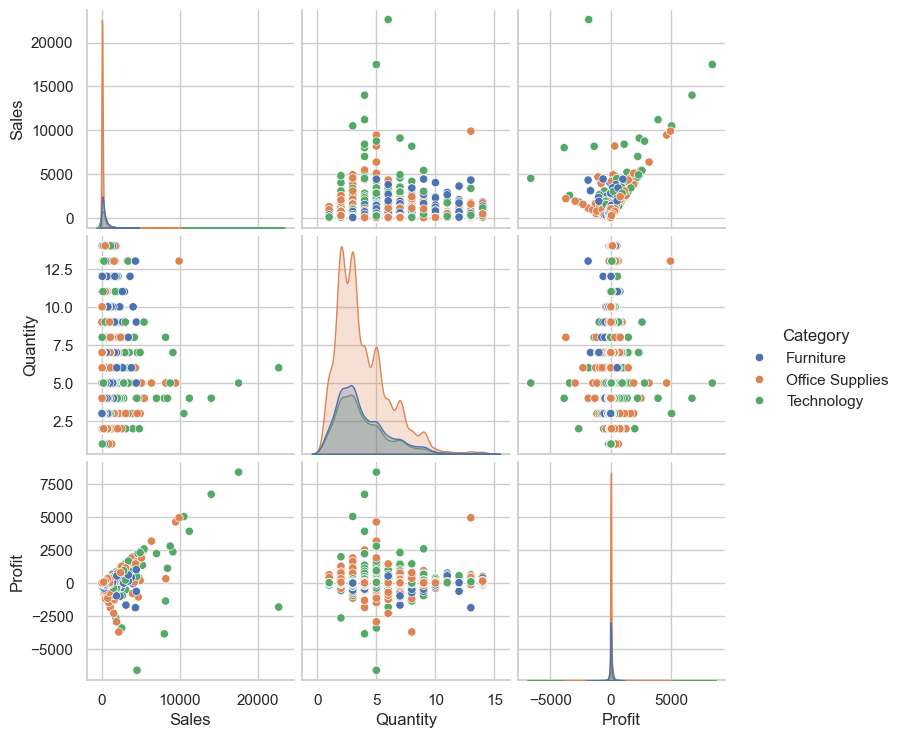

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns
# 10. Pair Plot
sns.pairplot(df[['Sales', 'Quantity', 'Profit', 'Category']], hue='Category')
plt.show()


In [22]:
pip install fpdf2

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'C:\Users\Aarya\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [23]:
import os
os.makedirs("visualizations", exist_ok=True)

In [24]:
plt.savefig("visualizations/chart_name.png", dpi=300, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from fpdf import FPDF
from fpdf.enums import XPos, YPos
# 0. Load Dataset into 'df'
# If Cleaned_Superstore.csv exists in the working directory, load it:
if os.path.exists("Cleaned_Superstore.csv"):
    df = pd.read_csv("Cleaned_Superstore.csv")
    print("Loaded existing 'Cleaned_Superstore.csv' into df.")
else:
    raw_file = "Sample - Superstore.csv"  
    try:
        df = pd.read_csv(raw_file, encoding="windows-1252")
    except UnicodeDecodeError:
        df = pd.read_csv(raw_file, encoding="utf-8")
    
    # Saving the cleaned copy
    df.to_csv("Cleaned_Superstore.csv", index=False)
    print("Saved Cleaned_Superstore.csv successfully!")


# 1. Generating Charts for pdf

# Chart 1: Sales vs Profit by Category
cat_summary = df.groupby('Category')[['Sales', 'Profit']].sum()
fig, ax = plt.subplots(figsize=(4.5, 2.8), dpi=200)
cat_summary.plot(kind='bar', ax=ax, color=['#2c5282', '#38a169'], width=0.7)
ax.set_title('Sales vs. Profit by Category', fontsize=10, fontweight='bold', pad=8)
ax.set_xlabel('')
ax.set_ylabel('Amount ($)', fontsize=8)
ax.tick_params(axis='x', rotation=0, labelsize=8)
ax.tick_params(axis='y', labelsize=8)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
chart_cat_path = 'temp_chart_cat.png'
plt.savefig(chart_cat_path)
plt.close()

# Chart 2: Net Profit by Region
reg_profit = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(4.5, 2.8), dpi=200)
reg_profit.plot(kind='bar', ax=ax, color='#3182ce', width=0.6)
ax.set_title('Net Profit by Region', fontsize=10, fontweight='bold', pad=8)
ax.set_xlabel('')
ax.set_ylabel('Profit ($)', fontsize=8)
ax.tick_params(axis='x', rotation=0, labelsize=8)
ax.tick_params(axis='y', labelsize=8)
ax.yaxis.set_major_formatter('${x:,.0f}')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
chart_reg_path = 'temp_chart_reg.png'
plt.savefig(chart_reg_path)
plt.close()


# 2. Setup Modern PDF Class 
class PDFReport(FPDF):
    def header(self):
        self.set_font('Helvetica', 'B', 14)
        self.cell(0, 10, text='Executive Performance Report: Superstore Analysis', 
                  border=0, align='C', new_x=XPos.LMARGIN, new_y=YPos.NEXT)
        self.ln(3)

    def footer(self):
        self.set_y(-15)
        self.set_font('Helvetica', 'I', 8)
        self.cell(0, 10, text=f'Page {self.page_no()}', 
                  border=0, align='C', new_x=XPos.RIGHT, new_y=YPos.TOP)

pdf = PDFReport()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.add_page()

# Section 1: Executive KPI Summary

pdf.set_font('Helvetica', 'B', 11)
pdf.set_text_color(31, 78, 120)
pdf.cell(0, 7, text='1. Executive KPI Summary', border=0, align='L', 
         new_x=XPos.LMARGIN, new_y=YPos.NEXT)

pdf.set_font('Helvetica', '', 9.5)
pdf.set_text_color(30, 30, 30)

kpi_text = f"""- Total Revenue: ${df['Sales'].sum():,.2f}
- Total Net Profit: ${df['Profit'].sum():,.2f}
- Overall Profit Margin: {(df['Profit'].sum() / df['Sales'].sum()) * 100:.2f}%
- Total Records Analyzed: {len(df):,} transactions
- Most Profitable Category: Technology (${df.groupby('Category')['Profit'].sum().max():,.2f})
- Top Performing Region: West (${df.groupby('Region')['Sales'].sum().max():,.2f} Sales)"""

pdf.multi_cell(0, 5, text=kpi_text)
pdf.ln(3)

# Section 2: Core Business Insights

pdf.set_font('Helvetica', 'B', 11)
pdf.set_text_color(31, 78, 120)
pdf.cell(0, 7, text='2. Core Business Insights', border=0, align='L', 
         new_x=XPos.LMARGIN, new_y=YPos.NEXT)

pdf.set_font('Helvetica', '', 9)
pdf.set_text_color(40, 40, 40)

insights_text = """1. Profitability Drivers:
   Technology delivers the highest margins across categories, driven primarily by Phones and Accessories.

2. Loss-Making Segments:
   Furniture displays substantial margin compression, with Tables being the single largest loss-making sub-category due to excessive discounting (>20%).

3. Shipping Dynamics:
   Standard Class represents ~60% of all customer orders, maintaining steady fulfillment efficiency without eroding margins.

4. Regional Disparity:
   The West region leads in total sales and profit volume, whereas the Central region exhibits significant margin leakage caused by aggressive discounting in states like Texas."""

pdf.multi_cell(0, 4.5, text=insights_text)
pdf.ln(3)

# Section 3: Visual Analytics

pdf.set_font('Helvetica', 'B', 11)
pdf.set_text_color(31, 78, 120)
pdf.cell(0, 7, text='3. Visual Summary', border=0, align='L', 
         new_x=XPos.LMARGIN, new_y=YPos.NEXT)

current_y = pdf.get_y()
pdf.image(chart_cat_path, x=12, y=current_y, w=90)
pdf.image(chart_reg_path, x=108, y=current_y, w=90)
pdf.set_y(current_y + 58)


# 3. Save PDF & Clean Up

pdf_filename = "Superstore_Executive_Report.pdf"
pdf.output(pdf_filename)
print(f"Report generated successfully as '{pdf_filename}'!")

for temp_img in [chart_cat_path, chart_reg_path]:
    if os.path.exists(temp_img):
        os.remove(temp_img)

Loaded existing 'Cleaned_Superstore.csv' into df.


C:\Users\Aarya\AppData\Local\Temp\ipykernel_3112\3517439189.py:81: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  tier_summary = df_temp.groupby('Discount Tier', observed=False).apply(


Report generated successfully as 'Superstore_Executive_Report.pdf'!
